# Risk Prediction Overview

## Phase 0: Directory location

In [1]:
import sys
from pathlib import Path

# Add the project root to Python path
project_root = Path.cwd().parent  # Goes up one level from notebooks/
sys.path.insert(0, str(project_root))

## Phase 1: Modules linked

In [2]:
# 1. Enable Auto-reloading
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

# 2. Import your heavy logic from your Python file
from core.gnn_layer.risk_predict import (
    fetch_graph_from_neo4j, 
    RiskEscalationGNN, 
    train_model, 
    evaluate_model
)

from core.kg_sna_layer.graph_builder import(
    AsyncKnowledgeGraphManager,
    wipe_sna_metrics
)

print("Environment linked and modules loaded successfully!")

c:\Users\dhara\anaconda3\envs\sna_oms_thesis\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Environment linked and modules loaded successfully!


In [3]:
import torch
import random
import numpy as np

# Lock the random seed for 100% reproducibility
seed = 42
torch.manual_seed(seed)
np.random.seed(seed)
random.seed(seed)

## Phase 2: Fetching data

In [4]:
from core.config import graph_base
print("Fetching graph data from Neo4j...")
kg_manager = AsyncKnowledgeGraphManager(graph_base.URL, graph_base.USER, graph_base.PASS)

Fetching graph data from Neo4j...


In [5]:
#Running wipe_sna_metrics() 
wipe_sna_metrics(graph_base.URL, graph_base.USER, graph_base.PASS)
baseline_data, enriched_data, reverse_mapping = fetch_graph_from_neo4j(graph_base.URL, graph_base.USER, graph_base.PASS)

print(f"Successfully loaded {baseline_data.num_nodes} nodes and {baseline_data.num_edges} edges before SNA calculations.")
print(f"Total High-Risk Edges (Class 1): {int(enriched_data.y.sum().item())}")

✅ Deleted SNA_TIE_STRENGTH edges.
✅ Removed structural metrics (betweenness, eigenvector, etc.) from nodes.
🧹 Graph successfully reset to its pure semantic state!
Successfully loaded 47 nodes and 124 edges before SNA calculations.
Total High-Risk Edges (Class 1): 3


In [6]:
#Running calculate_sna_metrics()
await kg_manager.calculate_sna_metrics()
baseline_data_sna, enriched_data_sna, reverse_mapping_sna = fetch_graph_from_neo4j(graph_base.URL, graph_base.USER, graph_base.PASS)

print(f"Successfully loaded {baseline_data_sna.num_nodes} nodes and {baseline_data_sna.num_edges} edges with SNA calculations.")
print(f"Total High-Risk Edges (Class 1): {int(enriched_data_sna.y.sum().item())}")

✅ Structural Metrics (Betweenness, Eigenvector, Closeness) updated.
Successfully loaded 47 nodes and 124 edges with SNA calculations.
Total High-Risk Edges (Class 1): 3


## Distribution

C:\Users\dhara\AppData\Local\Temp\ipykernel_7700\2328361671.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


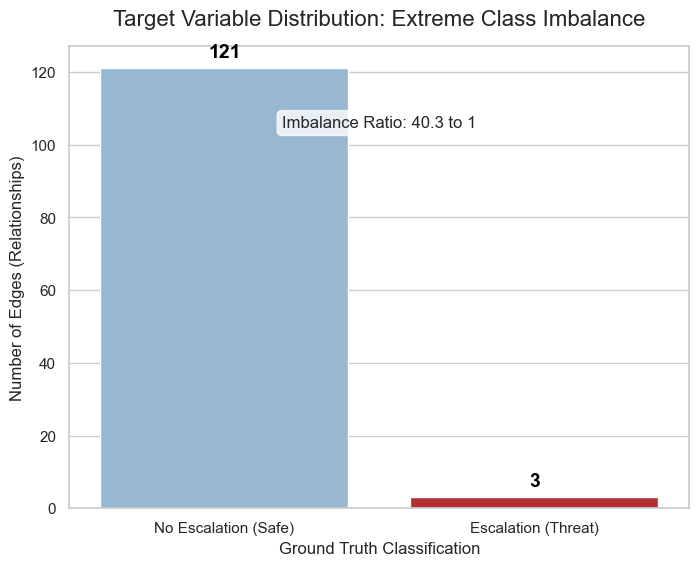

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Extract the ground-truth labels from your PyTorch Geometric object
# We use .cpu().numpy() to safely convert it from a PyTorch tensor to a standard array
y_true = enriched_data_sna.y.cpu().numpy()

# 2. Count the exact occurrences of 0s and 1s
unique, counts = np.unique(y_true, return_counts=True)
class_counts = dict(zip(unique, counts))

safe_count = class_counts.get(0, 0)
threat_count = class_counts.get(1, 0)

# 3. Set up the academic aesthetic
plt.figure(figsize=(8, 6))
sns.set_theme(style="whitegrid") # Clean, professional background

# 4. Create the bar chart
# We use a calm blue for Safe (0) and a harsh crimson for Threat (1) to tell a visual story
ax = sns.barplot(
    x=['No Escalation (Safe)', 'Escalation (Threat)'], 
    y=[safe_count, threat_count], 
    palette=['#8ebad9', '#cb181d'] 
)

# 5. Add exact numbers on top of the bars (Professors love exact numbers)
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='bottom', 
                fontsize=14, fontweight='bold', color='black', 
                xytext=(0, 5), textcoords='offset points')

# 6. Formatting for the thesis
plt.title('Target Variable Distribution: Extreme Class Imbalance', fontsize=16, pad=15)
plt.ylabel('Number of Edges (Relationships)', fontsize=12)
plt.xlabel('Ground Truth Classification', fontsize=12)

# Optional: Add a text box explaining the imbalance ratio
imbalance_ratio = safe_count / threat_count if threat_count > 0 else 0
textstr = f'Imbalance Ratio: {imbalance_ratio:.1f} to 1'
plt.text(0.5, 0.85, textstr, transform=ax.transAxes, fontsize=12,
         verticalalignment='top', horizontalalignment='center',
         bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

# 7. Save and display
# Assuming 'timestamp' is still defined in your notebook
import datetime
timestamp_dist = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
plt.savefig(f"class_distribution_{timestamp_dist}.png", dpi=300, bbox_inches='tight')

plt.show()

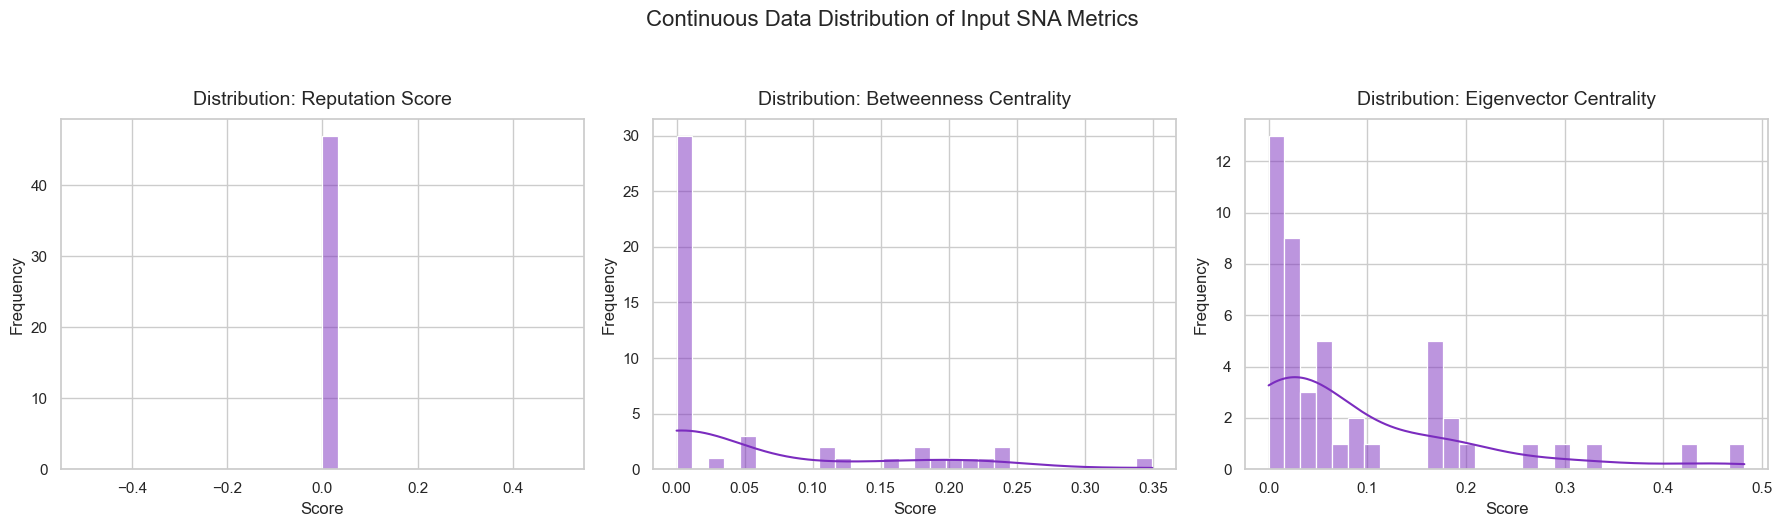

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from datetime import datetime

# 1. Extract the raw node features from your PyTorch object
# (We move it to CPU and convert to a numpy array)
node_features = enriched_data_sna.x.cpu().numpy()

# 2. Determine how many features you have
num_features = node_features.shape[1]

# 3. Set up a grid of plots side-by-side
fig, axes = plt.subplots(1, num_features, figsize=(6 * num_features, 5))

# Handle the case where there is only one feature (axes isn't an array)
if num_features == 1:
    axes = [axes]

# 4. Loop through each feature and plot its smooth distribution
# Create a list of the actual metric names
feature_names = ['Reputation Score', 'Betweenness Centrality', 'Eigenvector Centrality']

for i in range(num_features):
    sns.histplot(node_features[:, i], kde=True, ax=axes[i], color='#7b2cbf', bins=30)
    
    # Use the real names from the list!
    actual_name = feature_names[i] if i < len(feature_names) else f'Feature {i}'
    
    axes[i].set_title(f'Distribution: {actual_name}', fontsize=14, pad=10)
    axes[i].set_ylabel('Frequency')
    axes[i].set_xlabel('Score')

plt.suptitle('Continuous Data Distribution of Input SNA Metrics', fontsize=16, y=1.05)
plt.tight_layout()

# Save for your thesis
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
plt.savefig(f"feature_distributions_{timestamp}.png", dpi=300, bbox_inches='tight')

plt.show()

## Phase 3: Initialize and train models

In [ ]:
# Initialize
baseline_model = RiskEscalationGNN(num_node_features=1, hidden_channels=16)
enriched_model = RiskEscalationGNN(num_node_features=3, hidden_channels=16)

# Train
print("--- Training Baseline Model ---")
trained_baseline = train_model(baseline_model, baseline_data, epochs=100)
print("--- Training Baseline Model with SNA ---")
trained_baseline_sna = train_model(baseline_model, baseline_data_sna, epochs=100)

print("\n--- Training Enriched Model ---")
trained_enriched = train_model(enriched_model, enriched_data, epochs=100)
print("--- Training Enriched Model with SNA ---")
trained_enriched_sna = train_model(enriched_model, enriched_data_sna, epochs=100)

--- Training Baseline Model ---
Epoch 000 | Loss: 1.4050
Epoch 020 | Loss: 1.3013
Epoch 040 | Loss: 1.3650
Epoch 060 | Loss: 1.3883
Epoch 080 | Loss: 1.3796
--- Training Baseline Model with SNA ---
Epoch 000 | Loss: 1.3906
Epoch 020 | Loss: 1.3654
Epoch 040 | Loss: 1.4199
Epoch 060 | Loss: 1.3190
Epoch 080 | Loss: 1.4322

--- Training Enriched Model ---
Epoch 000 | Loss: 1.3535
Epoch 020 | Loss: 1.3528
Epoch 040 | Loss: 1.3528
Epoch 060 | Loss: 1.3528
Epoch 080 | Loss: 1.3528
--- Training Enriched Model with SNA ---
Epoch 000 | Loss: 1.3528
Epoch 020 | Loss: 1.3563
Epoch 040 | Loss: 1.2990
Epoch 060 | Loss: 1.2111
Epoch 080 | Loss: 0.9329


## Phase 4: AUC

ROC STUDY RESULTS:
WITHOUT SNA:
Baseline GNN -> AUC: 0.500 | Recall: 1.000
Enriched KG  -> AUC: 0.550 | Recall: 1.000
WITH SNA:
Baseline GNN -> AUC: 0.500 | Recall: 1.000
Enriched KG  -> AUC: 0.901 | Recall: 1.000


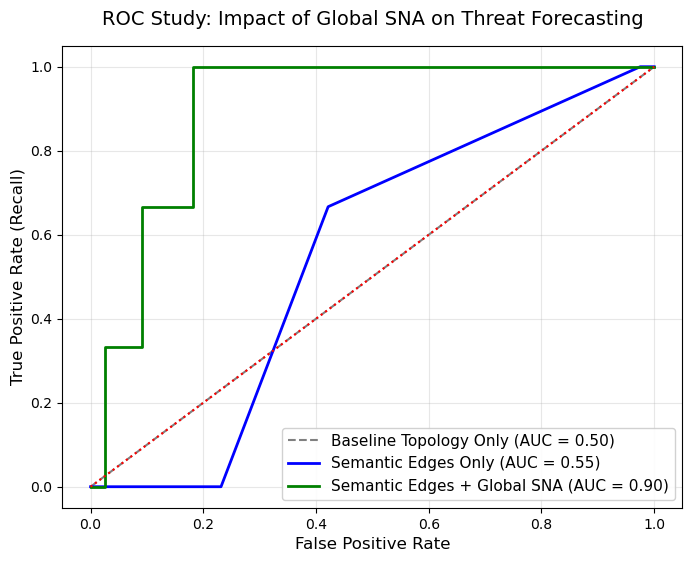

In [ ]:
from datetime import datetime
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
# Evaluate
base_auc, base_recall, y_true_b, preds_b = evaluate_model(trained_baseline, baseline_data)
enr_auc, enr_recall, y_true_e, preds_e = evaluate_model(trained_enriched, enriched_data)

# Evaluate with SNA
base_auc_sna, base_recall_sna, y_true_b_sna, preds_b_sna = evaluate_model(trained_baseline_sna, baseline_data_sna)
enr_auc_sna, enr_recall_sna, y_true_e_sna, preds_e_sna = evaluate_model(trained_enriched_sna, enriched_data_sna)


print("="*30)
print("ROC STUDY RESULTS:")
print("="*30)
print("WITHOUT SNA:")
print(f"Baseline GNN -> AUC: {base_auc:.3f} | Recall: {base_recall:.3f}")
print(f"Enriched KG  -> AUC: {enr_auc:.3f} | Recall: {enr_recall:.3f}")
print("WITH SNA:")
print(f"Baseline GNN -> AUC: {base_auc_sna:.3f} | Recall: {base_recall_sna:.3f}")
print(f"Enriched KG  -> AUC: {enr_auc_sna:.3f} | Recall: {enr_recall_sna:.3f}")

# Plotting the ROC Curve
fpr_b, tpr_b, _ = roc_curve(y_true_b, preds_b)
fpr_e, tpr_e, _ = roc_curve(y_true_e, preds_e)

#fpr_b_sna, tpr_b_sna, _ = roc_curve(y_true_b_sna, preds_b_sna)
fpr_e_sna, tpr_e_sna, _ = roc_curve(y_true_e_sna, preds_e_sna)

plt.figure(figsize=(8, 6))
plt.plot(fpr_b, tpr_b, linestyle='--', color='gray', label=f'Baseline Topology Only (AUC = {base_auc:.2f})')
plt.plot(fpr_e, tpr_e, color='blue', linewidth=2, label=f'Semantic Edges Only (AUC = {enr_auc:.2f})')
#plt.plot(fpr_b_sna, tpr_b_sna, linestyle='--', color='cyan', label=f'Baseline Binary GNN with SNA (AUC = {base_auc_sna:.2f})')
plt.plot(fpr_e_sna, tpr_e_sna, color='green', linewidth=2, label=f'Semantic Edges + Global SNA (AUC = {enr_auc_sna:.2f})')
plt.plot([0, 1], [0, 1], color='red', linestyle=':') 

plt.title('ROC Study: Impact of Global SNA on Threat Forecasting', fontsize=14, pad=15)
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate (Recall)', fontsize=12)
plt.legend(loc='lower right', fontsize=11, framealpha=0.9)
plt.grid(True, alpha=0.3)

filename_curve_auc = f"ablation_curves_{timestamp}.png"
# Save and show
plt.savefig(filename_curve_auc, dpi=300, bbox_inches='tight')
plt.show()

## Confusion Matrix (The Ground Truth)

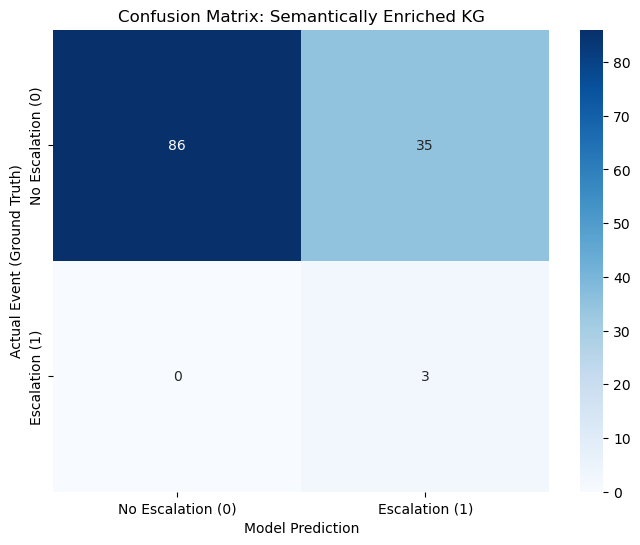

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
#import numpy as np
from sklearn.metrics import confusion_matrix

# 1. Convert raw probabilities into binary predictions using your optimized threshold
threshold = 0.30 
preds_binary_e_sna = (preds_e_sna >= threshold).astype(int)

# 2. Generate the confusion matrix using the Enriched Model's data
cm = confusion_matrix(y_true_e_sna, preds_binary_e_sna)

# 3. Plot the matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Escalation (0)', 'Escalation (1)'],
            yticklabels=['No Escalation (0)', 'Escalation (1)'])
plt.ylabel('Actual Event (Ground Truth)')
plt.xlabel('Model Prediction')
plt.title('Confusion Matrix: Semantically Enriched KG')

filename_conf_mtx = f"confusion_matrix_enriched_{timestamp}.png"
# Save and show
plt.savefig(filename_conf_mtx, dpi=300, bbox_inches='tight')
plt.show()

## Precision-Recall Curve

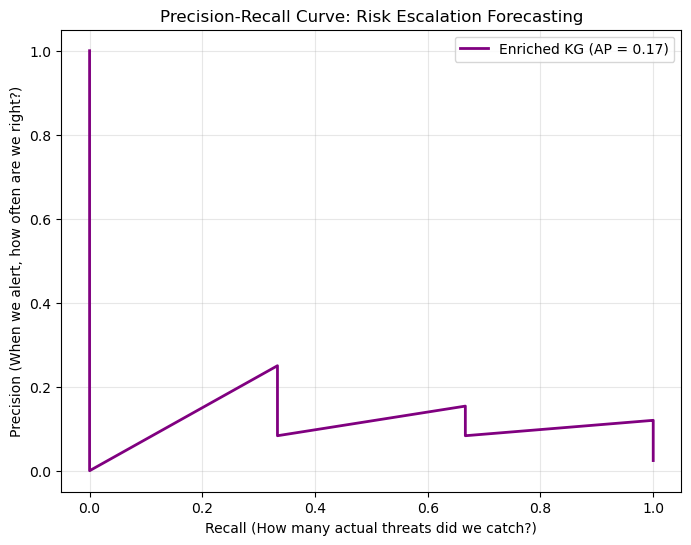

In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

# 1. Calculate Precision, Recall, and Average Precision (AP) scores
# Note: The PR curve inherently uses the raw probabilities (preds_e)
precision, recall, thresholds_pr = precision_recall_curve(y_true_e_sna, preds_e_sna)
ap_score = average_precision_score(y_true_e_sna, preds_e_sna)

# 2. Plot the curve
plt.figure(figsize=(8, 6))
plt.plot(recall, precision, color='purple', lw=2, 
         label=f'Enriched KG (AP = {ap_score:.2f})')

plt.title('Precision-Recall Curve: Risk Escalation Forecasting')
plt.xlabel('Recall (How many actual threats did we catch?)')
plt.ylabel('Precision (When we alert, how often are we right?)')
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)
plt.xlim([-0.05, 1.05])
plt.ylim([-0.05, 1.05])

filename_curve_pr = f"precision_recall_curve_{timestamp}.png"
# Save and show
plt.savefig(filename_curve_pr, dpi=300, bbox_inches='tight')
plt.show()

## Final reports

In [ ]:
import pandas as pd
from core.gnn_layer.risk_predict import generate_threat_report

# Generate alerts for any relationship with > 75% escalation probability
threat_alerts = generate_threat_report(trained_enriched_sna, enriched_data_sna, reverse_mapping_sna, threshold=0.75)

# 1. Convert to DataFrame and keep only the columns we need
df_alerts = pd.DataFrame(threat_alerts)[['source', 'target', 'probability']]

# 2. Rename columns for the professional output
df_alerts.columns = ['Source Node', 'Target Node', 'Risk Score']

# 3. Apply the gradient AND the percentage formatting in one smooth chain!
styled_table = df_alerts.style.background_gradient(
    subset=['Risk Score'], cmap='Reds', vmin=50.0, vmax=100.0
).format(
    # This magically turns 0.872 into '87.2%' without breaking the color math!
    {'Risk Score': "{:.1f}%"}
).set_caption("High-Risk Threat Escalation Report")

# 4. Save straight to HTML 
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
#html_filename = f"threat_table_final_{timestamp}.html"
#styled_table.to_html(html_filename)

#print(f"✅ Table generated and saved as {html_filename}")
# Display the table in the notebook
styled_table

,Source Node,Target Node,Risk Score
0,O'Reilly,Runner,87.2%
1,Unknown_Assailant,Torres,83.2%
2,Attacker,Batista,79.2%
3,O'Reilly,Younger Inmate,79.0%
4,O'Reilly,Assassination Target,78.9%
5,O'Reilly,Inmate,75.8%


In [ ]:
from neo4j import GraphDatabase
from core.config import graph_base

def enrich_alerts_with_predicates(alerts_list):
    print("🔍 Fetching original semantic predicates from Neo4j...")
    driver = GraphDatabase.driver(graph_base.URL, auth=(graph_base.USER, graph_base.PASS))
    
    with driver.session() as session:
        for alert in alerts_list:
            src = alert['source']
            tgt = alert['target']
            
            # Ask Neo4j what the original LLM-extracted relationship was
            # We explicitly ignore the mathematical SNA edges to get the real action
            query = """
            MATCH (a:Inmate {name: $src})-[r]->(b:Inmate {name: $tgt})
            WHERE type(r) <> 'SNA_TIE_STRENGTH'
            RETURN type(r) AS predicate LIMIT 1
            """
            result = session.run(query, src=src, tgt=tgt).single()
            
            # If Neo4j finds the predicate (e.g., 'ASSAULTS'), save it into the dictionary!
            if result and result['predicate']:
                alert['predicate'] = result['predicate']
            
    driver.close()
    print("✅ Enrichment complete!")
    return alerts_list

# Update your existing alerts list with the real words
threat_alerts = enrich_alerts_with_predicates(threat_alerts)

🔍 Fetching original semantic predicates from Neo4j...
✅ Enrichment complete!


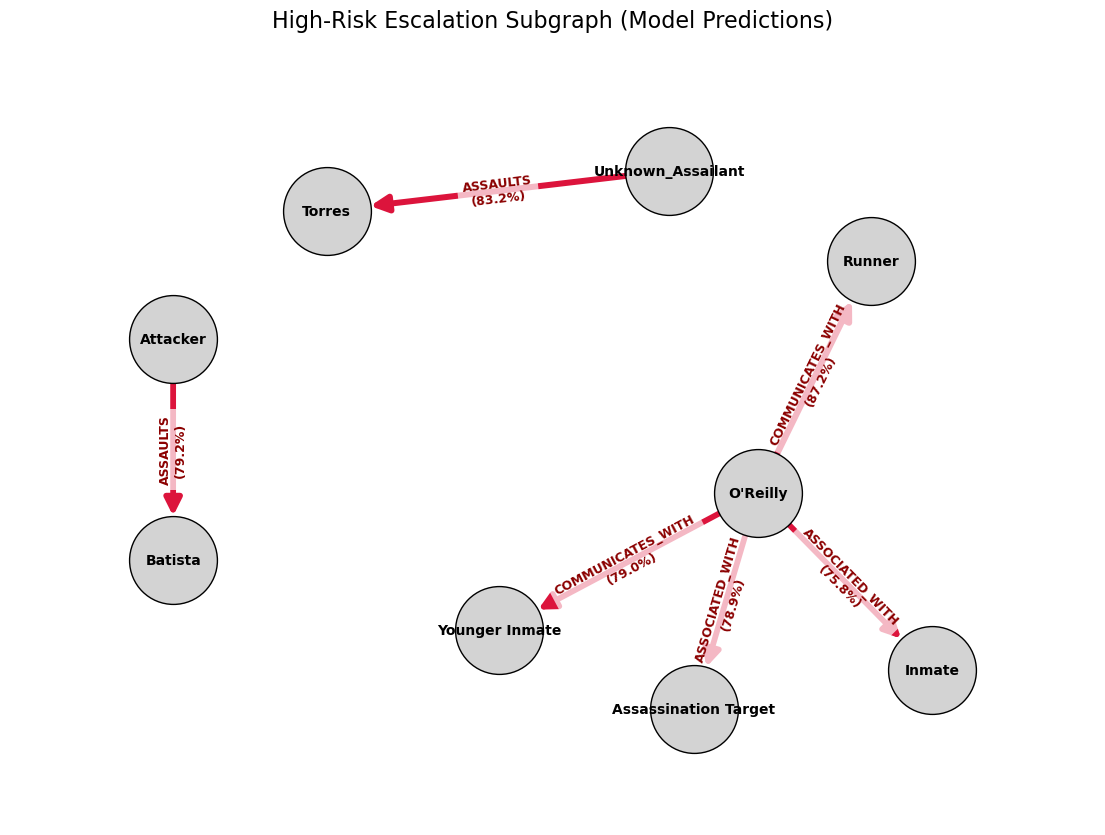

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt
from datetime import datetime

# 1. Create a blank, directed graph
G_threat = nx.DiGraph()

# 2. Add edges safely WITH LABELS
for alert in threat_alerts:
    src = alert['source']
    tgt = alert['target']
    
    # Format the probability as a clean percentage string
    prob_pct_string = f"{alert['probability']:.1f}%"
    
    # Get the predicate, defaulting to 'ESCALATES' if it's somehow missing
    predicate = alert.get('predicate', 'ESCALATES')
    
    # COMBINE THEM! The '\n' puts the percentage directly under the word
    arrow_label = f"{predicate}\n({prob_pct_string})"
    
    # Handle the weight math for the arrow thickness
    prob = float(alert['probability'])
    if prob > 1.0: 
        prob = prob / 100.0 
        
    G_threat.add_edge(src, tgt, weight=prob, label=arrow_label)

# 3. Set up a massive canvas to give the text room to breathe
plt.figure(figsize=(14, 10)) 

# FIX 1: Change to Kamada-Kawai layout. It is much smarter about 
# pushing disconnected nodes apart so lines don't cross over them!
# (If it still acts up, try changing this back to nx.spring_layout(G_threat, k=3.0))
pos = nx.kamada_kawai_layout(G_threat)

NODE_SIZE = 4000

# 4. Draw the Nodes
nx.draw_networkx_nodes(G_threat, pos, node_color='lightgrey', 
                       edgecolors='black', node_size=NODE_SIZE, alpha=1.0)

# Draw the Node Labels
nx.draw_networkx_labels(G_threat, pos, font_size=10, font_weight='bold')

# 5. Draw the Edges (Arrows)
edge_widths = [1 + (G_threat[u][v]['weight'] * 4) for u, v in G_threat.edges()]

# FIX 2: We changed rad=0.15 back to rad=0.0. 
# Straight lines are required so the text labels align perfectly!
nx.draw_networkx_edges(G_threat, pos, 
                       arrowstyle='-|>', 
                       arrowsize=25, 
                       edge_color='crimson', 
                       width=edge_widths, 
                       node_size=NODE_SIZE, 
                       connectionstyle="arc3,rad=0.0") 

# FIX 3: ADD THE EDGE LABELS (Predicates / Probabilities)
# This grabs the 'label' we assigned in Step 2 and draws it on the line
edge_labels = nx.get_edge_attributes(G_threat, 'label')
nx.draw_networkx_edge_labels(G_threat, pos, edge_labels=edge_labels, 
                             font_color='darkred', font_size=9, font_weight='bold',
                             # This adds a slight white background to the text so it's readable
                             bbox=dict(facecolor='white', edgecolor='none', alpha=0.7))

# 6. Formatting
plt.title("High-Risk Escalation Subgraph (Model Predictions)", fontsize=16, pad=20)
plt.margins(0.15) 
plt.axis('off')

# Save and show
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
plt.savefig(f"threat_subgraph_final_{timestamp}.png", dpi=300, bbox_inches='tight')

plt.show()